# EDA — ShopPulse (Olist)
Analyse exploratoire : distributions, saisonnalité, géographie.
Source : base PostgreSQL alimentée par le pipeline ETL.

In [1]:
import sys

sys.path.insert(0, "../src")
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
from shoppulse.data.db import read_sql

## 1. Distribution de la valeur des commandes

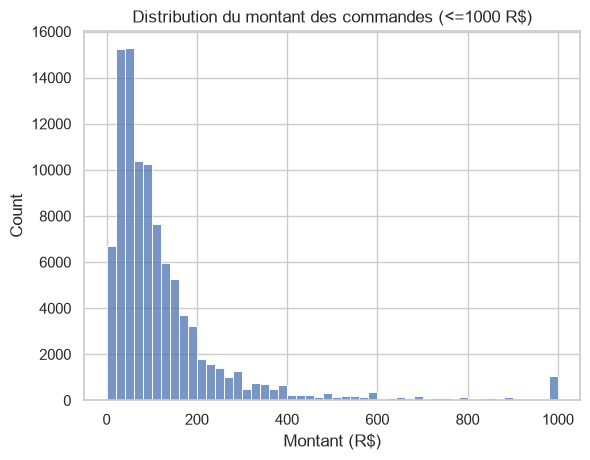

count    98666.000000
mean       137.754076
std        210.645145
min          0.850000
25%         45.900000
50%         86.900000
75%        149.900000
max      13440.000000
Name: montant, dtype: float64

In [2]:
val = read_sql("""SELECT order_id, SUM(price) AS montant FROM order_items GROUP BY order_id""")
ax = sns.histplot(val["montant"].clip(upper=1000), bins=50)
ax.set_title("Distribution du montant des commandes (<=1000 R$)")
ax.set_xlabel("Montant (R$)")
plt.show()
val["montant"].describe()

## 2. Distribution des notes d'avis

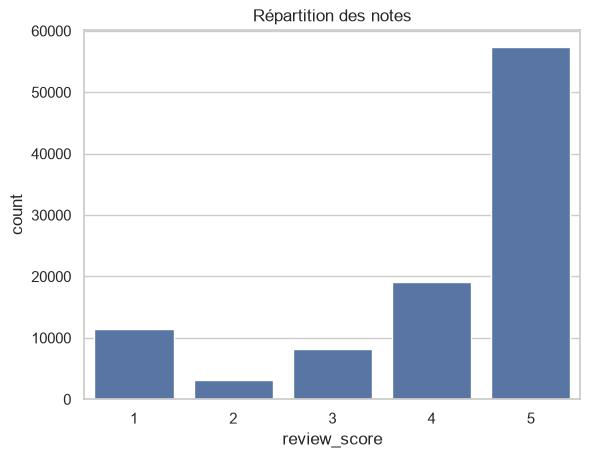

review_score
5    0.578
4    0.193
1    0.115
3    0.082
2    0.032
Name: proportion, dtype: float64

In [3]:
notes = read_sql("SELECT review_score FROM order_reviews")
ax = sns.countplot(x="review_score", data=notes)
ax.set_title("Répartition des notes")
plt.show()
notes["review_score"].value_counts(normalize=True).round(3)

## 3. Saisonnalité — commandes par mois

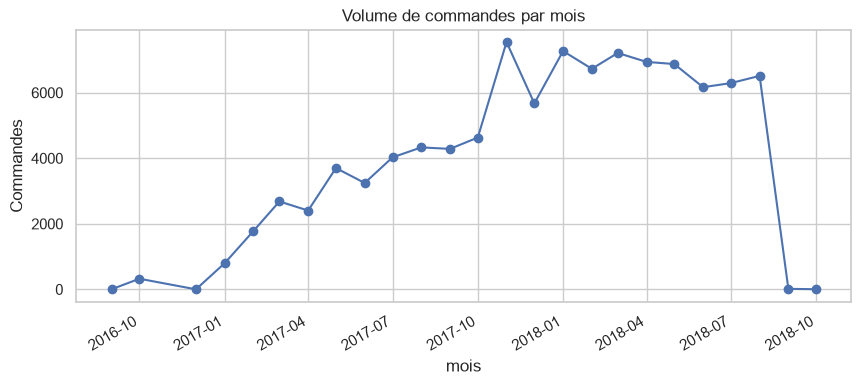

In [4]:
ts = read_sql(
    """SELECT DATE_TRUNC('month', order_purchase_timestamp) AS mois, COUNT(*) AS nb FROM orders WHERE order_purchase_timestamp IS NOT NULL GROUP BY 1 ORDER BY 1"""
)
ax = ts.plot(x="mois", y="nb", marker="o", legend=False, figsize=(10, 4))
ax.set_title("Volume de commandes par mois")
ax.set_ylabel("Commandes")
plt.show()

## 4. Analyse géographique — top états

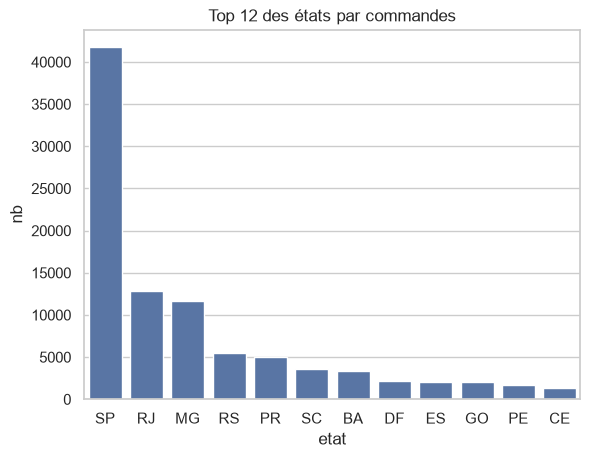

,etat,nb
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045


In [5]:
geo = read_sql(
    """SELECT c.customer_state AS etat, COUNT(*) AS nb FROM orders o JOIN customers c ON c.customer_id=o.customer_id GROUP BY 1 ORDER BY nb DESC LIMIT 12"""
)
ax = sns.barplot(x="etat", y="nb", data=geo)
ax.set_title("Top 12 des états par commandes")
plt.show()
geo.head()

## Synthèse
- Montants très asymétriques (longue traîne) → log-transformation pour le ML.
- Notes polarisées (beaucoup de 5, pic de 1) → lien avec la livraison (cf. stats).
- Forte saisonnalité et concentration géographique (São Paulo en tête).